In [312]:
from adabmDCA.fasta import import_from_fasta, decode_sequence, encode_sequence
from adabmDCA.sampling import gibbs_sampling
from adabmDCA.statmech import compute_energy
from tqdm.notebook import tqdm
import RNA

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import time
import torch

# use latex and font size 14
plt.rc('text', usetex=True)
plt.rc('font', size=14)

tokens = "ACGU-"
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."

In [313]:
# Load CSV into a pandas DataFrame
csv_path = "../Group_I_Intron/Matching_Data.csv"  # Replace with your actual CSV file path
df = pd.read_csv(csv_path)
df.head()

,names,activities_lowT,activities_highT,distances,sequences,DCA,SB
0,dca_f_mutations_129,-1.316208,-2.724580,55,GUGCCUUUCGACAGGAAACUUCGAAAGGAAUCCUGUCAAAUUCGGC...,37.074856,6.852815
1,dca_f_mutations_261,-2.664200,-999.000000,60,GUGCACUUUGUCGGGUUGCCGCAGAGUGAAUGUGGUCAAAUUCAAG...,33.076924,4.896689
2,dca_f_mutations_7,-2.736124,-999.000000,55,GUGCACUCAGCCGGGAAGCCGCAUAGUGGAUGUUCUCAAAUUCGGU...,28.189787,5.859439
3,dca_f_sequenza_1,-0.048592,1.969441,5,GUGCCUUUCGCCGGGAAACCACGAAAGGGAUGGUGUCAAAUUCGGC...,0.570879,5.453645
4,dca_f_sequenza_10,0.261965,1.722767,5,GUGCCUUGCGCCGGGAAACCACGCAAGGGAUGGUGUCAAAUUCGGC...,-0.357110,5.515907


In [314]:
# Load model
path_model = "../Group_I_Intron/modello_FC_T=1"
params_np = np.load(path_model)
params = {
    'bias': torch.tensor(params_np['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params_np['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

In [315]:
# Load wild type sequences to mutate
path_wt = "./WTs_to_thermo_fix.fasta"
wt_headers, wt_sequences_enc = import_from_fasta(path_wt, tokens=tokens)
wt_sequences_enc = wt_sequences_enc[:,3:-1]  # Remove the added GUG and G
wt_sequences = torch.nn.functional.one_hot(torch.tensor(wt_sequences_enc), num_classes=5).float().to('cuda')

In [317]:
# mapping from new to old headers
fname_mapping = "../lore/WTs_to_thermo_fix_mapping_names.txt"
df_mapping = pd.read_csv(fname_mapping, sep=" ", header=None, names=["old", "new"])
header_mapping = {row['new']: row['old'] for _, row in df_mapping.iterrows()}

In [318]:
# select a WT sequence
idx_wt = 1
wt_seq = wt_sequences[idx_wt:idx_wt+1].squeeze(0)  # Shape (L, q)
wt_header = wt_headers[idx_wt]

wt_energy = compute_energy(wt_seq.unsqueeze(0), params=params).item()

# find the corresponding row in the dataframe
row = df[df["names"] == header_mapping[wt_header]].reset_index(drop=True)

print("Sequence name:", wt_header)
print("DCA score:", wt_energy)
print("Distance from Azoarcus:", row["distances"].values[0])
print("T = 37C activity:", row["activities_lowT"].values[0])
print("T = 60C activity:", row["activities_highT"].values[0])

Sequence name: wt_2
DCA score: 79.8155517578125
Distance from Azoarcus: 25
T = 37C activity: -1.2325486734560251
T = 60C activity: -999.0


In [68]:
# Import a mutant
idx_mutant = 6
#path_mutants = "../lore/old/dca_f_sequenza_682_mutants_5-10_lowDCA_lowSB_beta1.25_sb-3.00.csv"
#df_mutants = pd.read_csv(path_mutants)
#mutant_seq_str = df_mutants.iloc[idx_mutant]["sequence"]

path_mutants = "../lore/old/wt_1_34.fasta"
mutant_seqs_str = import_from_fasta(path_mutants)[1]
mutant_seqs_enc = encode_sequence(mutant_seqs_str, tokens=tokens)
mutant_seqs = torch.nn.functional.one_hot(torch.tensor(mutant_seqs_enc), num_classes=5).float().to('cuda')
mutant_seq = mutant_seqs[idx_mutant]

mutant_seq_enc = encode_sequence(mutant_seq_str, tokens=tokens)
mutant_seq = torch.nn.functional.one_hot(torch.tensor(mutant_seq_enc).unsqueeze(0), num_classes=5).float().to('cuda').squeeze(0)
print(mutant_seq.shape, wt_seq.shape)

torch.Size([193, 5]) torch.Size([193, 5])


In [65]:
def compute_logp(seq, params):
    L, q = seq.shape
    logp = []
    for residue_idx in range(L):
        couplings_residue = params["coupling_matrix"][residue_idx].view(q, L * q)
        logit_residue = (params["bias"][residue_idx] + seq.reshape(L * q) @ couplings_residue.T) # (q,)
        norm_logit_residue = logit_residue - torch.logsumexp(logit_residue, dim=0)
        logp.append(norm_logit_residue @ seq[residue_idx])
    return torch.stack(logp)

In [66]:
logp_wt = compute_logp(wt_seq, params).cpu().numpy()
logp_mutant = compute_logp(mutant_seq, params).cpu().numpy()

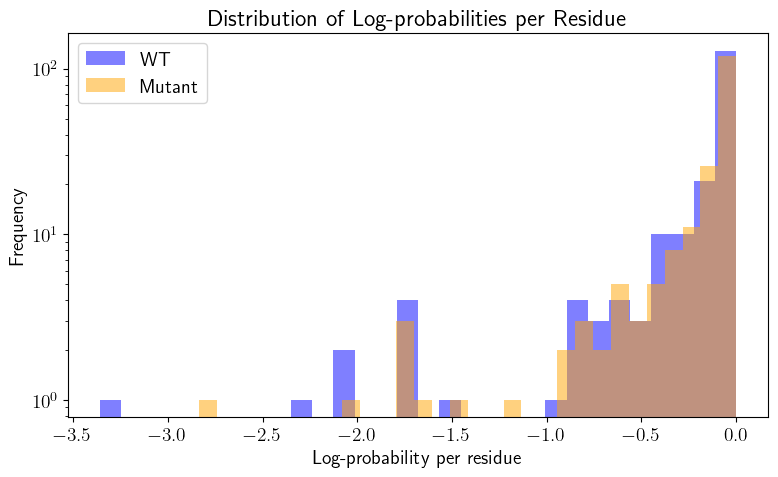

In [67]:
# plot histogram of logp values
plt.figure(figsize=(8, 5))
plt.hist(logp_wt, bins=30, alpha=0.5, label='WT', color='blue')
plt.hist(logp_mutant, bins=30, alpha=0.5, label='Mutant', color='orange')
plt.xlabel('Log-probability per residue')
plt.ylabel('Frequency')
plt.title('Distribution of Log-probabilities per Residue')
plt.legend()
plt.yscale('log')
plt.tight_layout()

In [69]:
min_logp_mutant = []
for mutant in mutant_seqs:
    min_logp_mutant.append(torch.min(compute_logp(mutant, params=params)).item())

In [70]:
min_logp_wt = torch.min(compute_logp(wt_seq, params=params)).item()

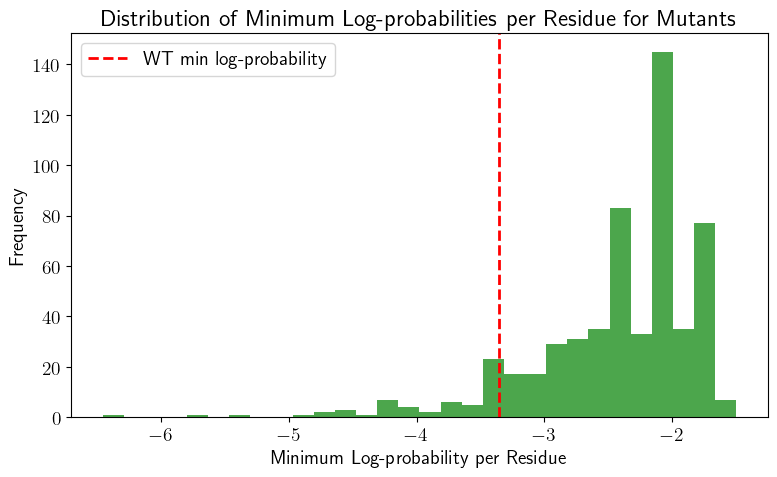

In [73]:
# make a histogram of min_logp_mutant
plt.figure(figsize=(8, 5))
plt.hist(min_logp_mutant, bins=30, alpha=0.7, color='green')
plt.axvline(min_logp_wt, color='red', linestyle='dashed', linewidth=2, label='WT min log-probability')
plt.xlabel('Minimum Log-probability per Residue')
plt.ylabel('Frequency')
plt.title('Distribution of Minimum Log-probabilities per Residue for Mutants')
#plt.yscale('log')
plt.legend()
plt.tight_layout()

## Test on experimental data from Azoarcus paper

In [319]:
path_fasta = "../lore/paper_azo/over_quality_threshold.fasta"
path_metadata = "../lore/paper_azo/over_quality_threshold.dat"
df_metadata = pd.read_csv(path_metadata, sep=" ", names=["model", "header", "useless_1", "useless_2", "distance_from_azo", "activity"])
headers, sequences = import_from_fasta(path_fasta)
df_sequences = pd.DataFrame({"header": headers, "sequence": sequences})
df = pd.merge(df_metadata, df_sequences, left_on="header", right_on="header").filter(items=["model", "header", "distance_from_azo", "activity", "sequence"])
activity_threshold = -2.76
df["is_active"] = df["activity"] > activity_threshold
df.to_csv("../lore/paper_azo/summary_data.csv", index=False)
print(len(df))
df.head()
#sequences_enc = sequences_enc[:,3:-1]  # Remove the added GUG and G

24071


,model,header,distance_from_azo,activity,sequence,is_active
0,dca_sb,dca_sb_0_10_1_1_10,9,-0.464314,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
1,dca_sb,dca_sb_0_10_2_1_10,9,-0.414826,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
2,dca_sb,dca_sb_0_10_3_1_10,9,-0.268490,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
3,dca_sb,dca_sb_0_10_4_1_10,9,-0.385578,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True
4,dca_sb,dca_sb_0_10_5_1_10,9,-0.580218,GUGCCUUGCACCGGGAAACCGUGUAAGGGAUGGUGUCAAAUUCGGU...,True


In [320]:
def compute_free_energy(sequences, dot_bracket_structure):
    free_energies = []
    for sequence in sequences:
        fc = RNA.fold_compound(sequence)
        free_energy = fc.eval_structure(dot_bracket_structure)
        free_energies.append(free_energy)
    return free_energies

In [321]:
FE = compute_free_energy(df["sequence"].tolist(), dot_bracket_with_pk)
df["FE"] = FE

sequences_enc = encode_sequence(df["sequence"].tolist(), tokens=tokens)
sequences_enc = sequences_enc[:, 3:-1]  # Remove the added GUG and G
sequences_oh = torch.nn.functional.one_hot(torch.tensor(sequences_enc), num_classes=5).float().to('cuda')
dca_scores = compute_energy(sequences_oh, params=params).cpu().numpy()
df["DCA"] = dca_scores

df.head()

,model,header,distance_from_azo,activity,sequence,is_active,FE,DCA
0,dca_sb,dca_sb_0_10_1_1_10,9,-0.464314,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True,-66.800003,72.669937
1,dca_sb,dca_sb_0_10_2_1_10,9,-0.414826,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True,-65.400002,69.506638
2,dca_sb,dca_sb_0_10_3_1_10,9,-0.268490,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True,-66.099998,69.645767
3,dca_sb,dca_sb_0_10_4_1_10,9,-0.385578,GUGCCUUGCGCCGGGAAACCGCGUAAGGGAUGGUGUCAAAUUCGGU...,True,-63.599998,75.604355
4,dca_sb,dca_sb_0_10_5_1_10,9,-0.580218,GUGCCUUGCACCGGGAAACCGUGUAAGGGAUGGUGUCAAAUUCGGU...,True,-63.900002,72.980347


Correlation coefficient between DCA and Free Energy: 0.2355


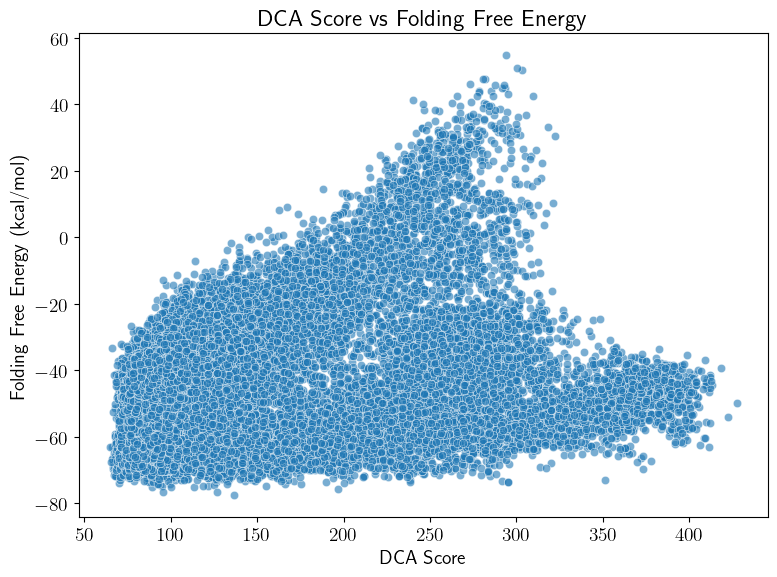

In [322]:
# scatter plot of DCA vs FE using seaborn
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="DCA", y="FE", alpha=0.6)
plt.xlabel('DCA Score')
plt.ylabel('Folding Free Energy (kcal/mol)')
plt.title('DCA Score vs Folding Free Energy')

# compute correlation coefficient
correlation = df["DCA"].corr(df["FE"])
print(f"Correlation coefficient between DCA and Free Energy: {correlation:.4f}")

plt.tight_layout()

Correlation coefficient between Distance from Azoarcus and DCA: 0.7086


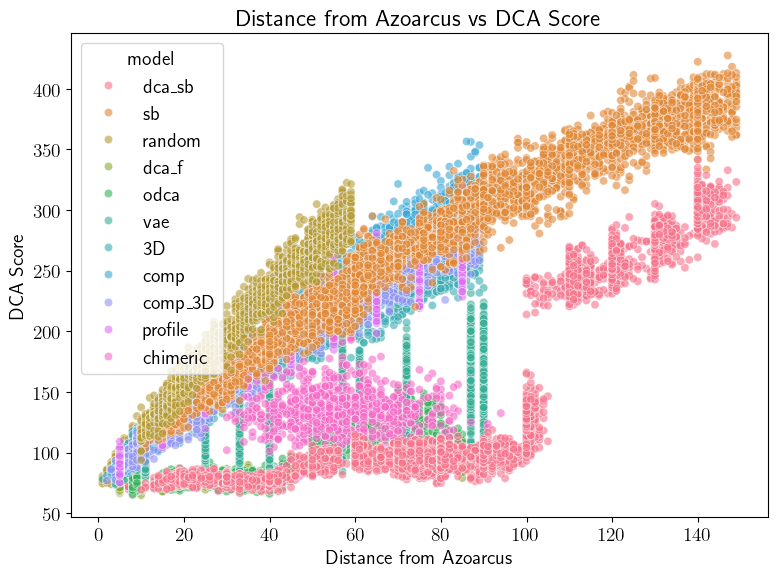

In [323]:
# scatter plot of distance from Azoarcus vs DCA
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="distance_from_azo", y="DCA", alpha=0.6, hue="model")
plt.xlabel('Distance from Azoarcus')
plt.ylabel('DCA Score')
plt.title('Distance from Azoarcus vs DCA Score')

correlation = df["distance_from_azo"].corr(df["DCA"])
print(f"Correlation coefficient between Distance from Azoarcus and DCA: {correlation:.4f}")

plt.tight_layout()

In [325]:
# select sb model, distance from Azoarcus between 25 and 35
df_sb = df[(df["model"] == "sb") & (df["distance_from_azo"] > 25) & (df["distance_from_azo"] < 35)]
print(len(df_sb))

326


In [328]:
from concurrent.futures import ProcessPoolExecutor
from functools import partial

def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

In [329]:
# compute BPP scores and DCA energies for all sequences in df_sb
sb_sequences_enc = encode_sequence(df_sb["sequence"].tolist(), tokens=tokens)
sb_sequences_enc = sb_sequences_enc[:, 3:-1]  # Remove the added GUG and G
sb_sequences_oh = torch.nn.functional.one_hot(torch.tensor(sb_sequences_enc), num_classes=5).float().to('cuda')
dca_scores_sb = compute_energy(sb_sequences_oh, params=params).cpu().numpy()
df_sb["DCA"] = dca_scores_sb
bpp_scores_sb = compute_bpp_scores(sb_sequences_oh, dot_bracket_with_pk, num_workers=20)
df_sb["BPP"] = bpp_scores_sb

/tmp/ipykernel_104350/349601128.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sb["DCA"] = dca_scores_sb
/tmp/ipykernel_104350/349601128.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sb["BPP"] = bpp_scores_sb


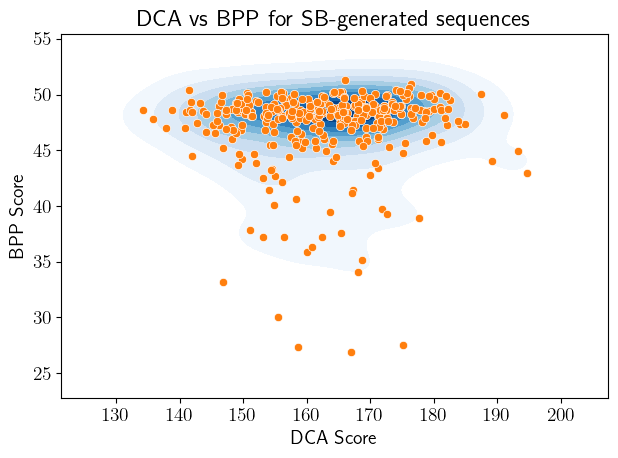

In [332]:
sns.kdeplot(data=df_sb, x="DCA", y="BPP", fill=True, cmap="Blues", thresh=0.05)
sns.scatterplot(data=df_sb, x="DCA", y="BPP", alpha=1.0)
plt.xlabel('DCA Score')
plt.ylabel('BPP Score')
plt.title('DCA vs BPP for SB-generated sequences')
plt.tight_layout()

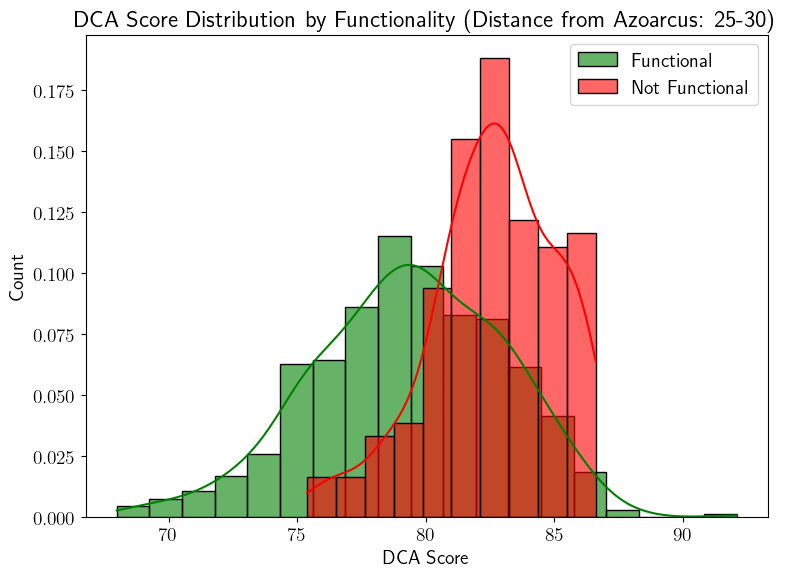

In [278]:
dmin, dmax = 25, 30
models = ["dca_f", "dca_sb", "odca"]
plt.figure(figsize=(8, 6))
df_filtered = df[(df["distance_from_azo"] >= dmin) & (df["distance_from_azo"] <= dmax)]
df_filtered = df_filtered[df_filtered["model"].isin(models)]
df_functional = df_filtered[df_filtered["is_active"]]
df_not_functional = df_filtered[~df_filtered["is_active"]]
sns.histplot(data=df_functional, x="DCA", color='green', label='Functional', alpha=0.6, kde=True, stat="density")
sns.histplot(data=df_not_functional, x="DCA", color='red', label='Not Functional', alpha=0.6, kde=True, stat="density")
plt.xlabel('DCA Score')
plt.ylabel('Count')
plt.legend()
plt.title('DCA Score Distribution by Functionality (Distance from Azoarcus: {}-{})'.format(dmin, dmax))
plt.tight_layout()

In [231]:
def compute_logp(seq, params):
    L, q = seq.shape
    logp = []
    for residue_idx in range(L):
        couplings_residue = params["coupling_matrix"][residue_idx].view(q, L * q)
        logit_residue = (params["bias"][residue_idx] + seq.reshape(L * q) @ couplings_residue.T) # (q,)
        norm_logit_residue = logit_residue - torch.logsumexp(logit_residue, dim=0)
        logp.append(norm_logit_residue @ seq[residue_idx])
    return torch.stack(logp)

# batched version of compute_logp
def compute_logp_batched(seqs, params):
    B, L, q = seqs.shape
    logp = []
    for residue_idx in range(L):
        couplings_residue = params["coupling_matrix"][residue_idx].view(q, L * q)
        logit_residue = (params["bias"][residue_idx] + seqs.reshape(B, L * q) @ couplings_residue.T) # (B, q)
        norm_logit_residue = logit_residue - torch.logsumexp(logit_residue, dim=1, keepdim=True)
        logp.append(torch.sum(norm_logit_residue * seqs[:, residue_idx, :], dim=1))  # (B,)
    return torch.stack(logp, dim=1)  # (B, L)

def criterium_logp(logp: torch.Tensor, num_worst=1):
    if num_worst == 1:
        return torch.min(logp).item()
    else:
        logp_sorted = torch.sort(logp).values
    return torch.mean(logp_sorted[:num_worst]).item()

# batched version of criterium_logp
def criterium_logp_batched(logp: torch.Tensor, num_worst=1):
    if num_worst == 1:
        return torch.min(logp, dim=1).values.cpu().numpy()
    else:
        logp_sorted = torch.sort(logp, dim=1).values
        return torch.mean(logp_sorted[:, :num_worst], dim=1).cpu().numpy()

Correlation coefficient between LogP and DCA: -0.8583
Correlation coefficient between LogP and DCA (LogP < -0.22, 406 seqs): -0.6828


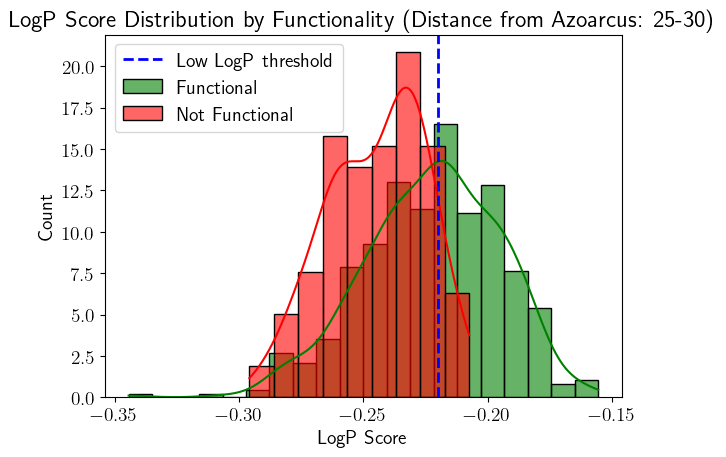

In [289]:
num_worst = 200

sequences_filtered_enc = encode_sequence(df_filtered["sequence"].tolist(), tokens=tokens)
sequences_filtered_enc = sequences_filtered_enc[:, 3:-1]  # Remove the added GUG and G
sequences_filtered_oh = torch.nn.functional.one_hot(torch.tensor(sequences_filtered_enc), num_classes=5).float().to('cuda')
logp_scores = criterium_logp_batched(compute_logp_batched(sequences_filtered_oh, params=params), num_worst=num_worst)
df_filtered["logp"] = logp_scores

df_functional = df_filtered[df_filtered["is_active"]]
df_not_functional = df_filtered[~df_filtered["is_active"]]
sns.histplot(data=df_functional, x="logp", color='green', label='Functional', alpha=0.6, kde=True, stat="density")
sns.histplot(data=df_not_functional, x="logp", color='red', label='Not Functional', alpha=0.6, kde=True, stat="density")
plt.xlabel('LogP Score')
plt.ylabel('Count')
plt.legend()
plt.title('LogP Score Distribution by Functionality (Distance from Azoarcus: {}-{})'.format(dmin, dmax))


# correlation logp and DCA
correlation_logp_dca = df_filtered["logp"].corr(df_filtered["DCA"])
print(f"Correlation coefficient between LogP and DCA: {correlation_logp_dca:.4f}")

# correlation logp and DCA when logp < -2.5
low_logp_th = -0.22
df_low_logp = df_filtered[df_filtered["logp"] < low_logp_th]
correlation_logp_dca_low = df_low_logp["logp"].corr(df_low_logp["DCA"])
print(f"Correlation coefficient between LogP and DCA (LogP < {low_logp_th}, {len(df_low_logp)} seqs): {correlation_logp_dca_low:.4f}")

plt.axvline(low_logp_th, color='blue', linestyle='dashed', linewidth=2, label='Low LogP threshold')
plt.legend()

plt.tight_layout()

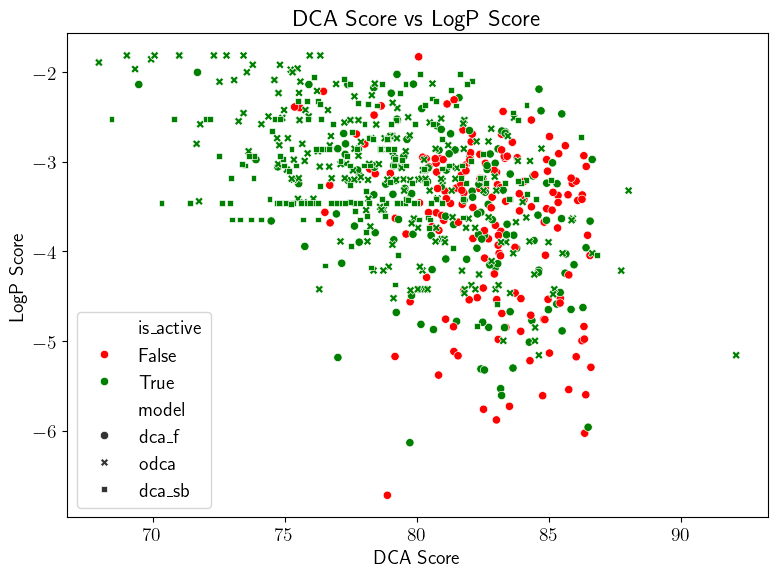

In [233]:
# scatterplot of DCA vs logp with color by model, marker by is_active
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_filtered, x="DCA", y="logp", hue="is_active", style="model", alpha=1.0, palette={True: 'green', False: 'red'})
plt.xlabel('DCA Score')
plt.ylabel('LogP Score')
plt.title('DCA Score vs LogP Score')
plt.tight_layout()

<Axes: xlabel='DCA', ylabel='Count'>

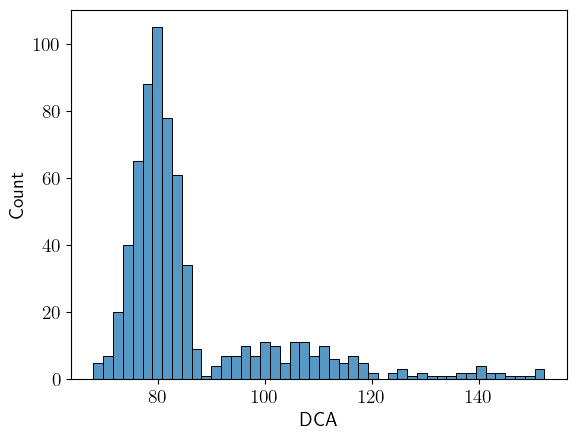

In [264]:
df_filtered = df[(df["is_active"] == 1) & (df["distance_from_azo"] >= 25) & (df["distance_from_azo"] <= 30)]

sns.histplot(df_filtered, x="DCA")
#plt.yscale('log')

### Test on generated mutants

In [237]:
old_wt_name = "dca_f_sequenza_682"

# low SB mutants (lsb)
path_mutants_lsb = f"../lore/old/{old_wt_name}_mutants_5-10_lowDCA_lowSB_beta1.25_sb-3.00.csv"
df_mutants_lsb = pd.read_csv(path_mutants_lsb)
mutants_lsb_enc = encode_sequence(df_mutants_lsb["sequence"].tolist(), tokens=tokens)
mutants_lsb_oh = torch.nn.functional.one_hot(torch.tensor(mutants_lsb_enc), num_classes=5).float().to('cuda')
print("Mutants lsb loaded:", mutants_lsb_oh.shape)

# high SB mutants (hsb)
path_mutants_hsb = f"../lore/wt_1_mut_lowDCA_highSB_beta1.5_sb2.0.fasta"
headers_hsb, mutant_hsb_enc = import_from_fasta(path_mutants_hsb, tokens=tokens)
mutants_hsb_oh = torch.nn.functional.one_hot(torch.tensor(mutant_hsb_enc), num_classes=5).float().to('cuda')
print("Mutants hsb loaded:", mutants_hsb_oh.shape)

# load wild type sequence
path_wt_to_thermo = "../lore/WTs_to_thermo_fix.fasta"
headers_wt, sequences_wt_enc = import_from_fasta(path_wt_to_thermo, tokens=tokens)
sequences_wt_enc = sequences_wt_enc[:,3:-1]  # Remove the added GUG and G
sequences_wt_oh = torch.nn.functional.one_hot(torch.tensor(sequences_wt_enc), num_classes=5).float().to('cuda')

# mapping from old to new headers
path_mapping = "../lore/WTs_to_thermo_fix_mapping_names.txt"
df_mapping = pd.read_csv(path_mapping, sep=" ", names=["old_name", "new_name"])
mapping_dict = dict(zip(df_mapping["old_name"], df_mapping["new_name"]))
new_wt_name = mapping_dict[old_wt_name]
print("Wild type name:", new_wt_name)
wt_idx = list(headers_wt).index(new_wt_name)
wt_seq = sequences_wt_oh[wt_idx]  # Shape (L, q)
print("Wild type sequence loaded:", wt_seq.shape)

Mutants lsb loaded: torch.Size([50, 193, 5])
Mutants hsb loaded: torch.Size([425, 193, 5])
Wild type name: wt_1
Wild type sequence loaded: torch.Size([193, 5])


In [307]:
num_worst = 1

logp_wt = compute_logp(wt_seq, params)
energy_wt = compute_energy(wt_seq.unsqueeze(0), params=params).item()
logp_wt_crit = criterium_logp(logp_wt, num_worst=num_worst)

logp_mutants_lsb = compute_logp_batched(mutants_lsb_oh, params=params)
logp_mutants_lsb_crit = criterium_logp_batched(logp_mutants_lsb, num_worst=num_worst)
energy_mutants_lsb = compute_energy(mutants_lsb_oh, params=params).cpu().numpy()

logp_mutants_hsb = compute_logp_batched(mutants_hsb_oh, params=params)
logp_mutants_hsb_crit = criterium_logp_batched(logp_mutants_hsb, num_worst=num_worst)
energy_mutants_hsb = compute_energy(mutants_hsb_oh, params=params).cpu().numpy()

<Figure size 800x500 with 0 Axes>

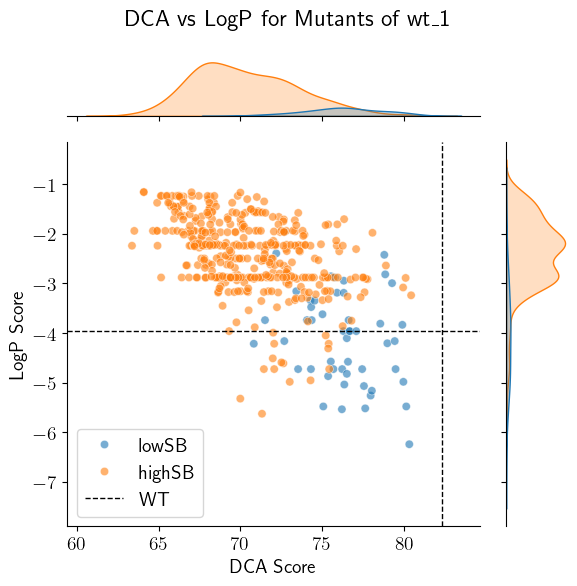

In [308]:
fig = plt.figure(figsize=(8, 5))
delta_logp_lsb = logp_mutants_lsb - logp_wt
delta_logp_lsb_crit = criterium_logp_batched(delta_logp_lsb, num_worst=num_worst)
df_mutants_lsb_analysis = pd.DataFrame({
    "logp": logp_mutants_lsb_crit,
    "DCA": energy_mutants_lsb,
    "delta_logp": delta_logp_lsb_crit,
    "type": ["lowSB"] * len(logp_mutants_lsb_crit)
})

delta_logp_hsb = logp_mutants_hsb - logp_wt
delta_logp_hsb_crit = criterium_logp_batched(delta_logp_hsb, num_worst=num_worst)
df_mutants_hsb_analysis = pd.DataFrame({
    "logp": logp_mutants_hsb_crit,
    "DCA": energy_mutants_hsb,
    "delta_logp": delta_logp_hsb_crit,
    "type": ["highSB"] * len(logp_mutants_hsb_crit)
})

df_mutants_analysis = pd.concat([df_mutants_lsb_analysis, df_mutants_hsb_analysis], ignore_index=True)
g = sns.jointplot(data=df_mutants_analysis, x="DCA", y="logp", hue="type", alpha=0.6)
plt.axhline(logp_wt_crit, color='black', linestyle='dashed', linewidth=1)
plt.axvline(energy_wt, color='black', linestyle='dashed', linewidth=1, label='WT')
plt.xlabel('DCA Score')
plt.ylabel('LogP Score')
g.fig.suptitle('DCA vs LogP for Mutants of {}'.format(new_wt_name))
plt.legend()
plt.tight_layout()

Number of mutants in DCA range (60-85): 475


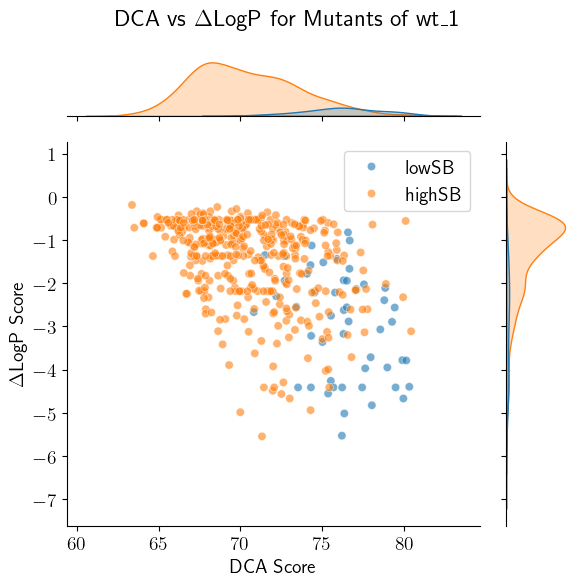

In [310]:
# select DCA range
DCA_min, DCA_max = 60, 85
df_mutants_analysis_filtered = df_mutants_analysis[(df_mutants_analysis["DCA"] >= DCA_min) & (df_mutants_analysis["DCA"] <= DCA_max)]
print("Number of mutants in DCA range ({}-{}): {}".format(DCA_min, DCA_max, len(df_mutants_analysis_filtered)))

g = sns.jointplot(data=df_mutants_analysis_filtered, x="DCA", y="delta_logp", hue="type", alpha=0.6)
plt.xlabel('DCA Score')
plt.ylabel(r'$\Delta$LogP Score')
g.fig.suptitle(r'DCA vs $\Delta$LogP for Mutants of {}'.format(new_wt_name))
plt.legend()
plt.tight_layout()

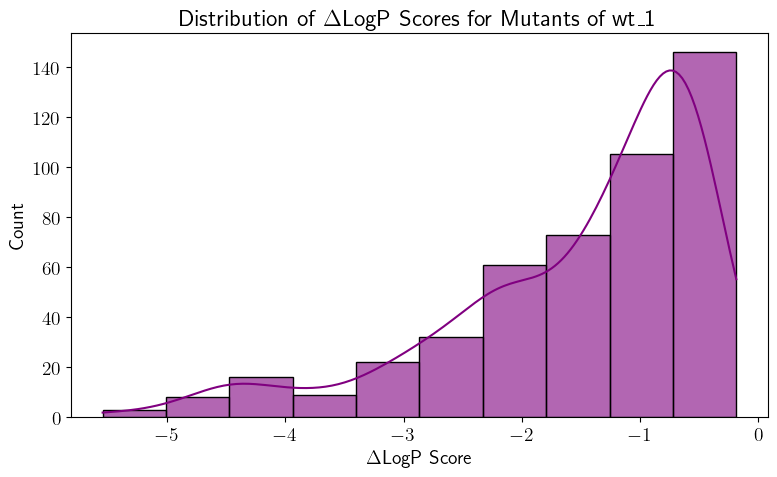

In [311]:
fig = plt.figure(figsize=(8, 5))
sns.histplot(data=df_mutants_analysis, x="delta_logp", bins=10, kde=True, color='purple', alpha=0.6)
plt.xlabel(r'$\Delta$LogP Score')
plt.ylabel('Count')
plt.title(r'Distribution of $\Delta$LogP Scores for Mutants of {}'.format(new_wt_name))
plt.tight_layout()